In [1]:
import cv2
import mediapipe as mp
import csv
import numpy as np

In [2]:
video_path = './Data/videos/20240301_173556.mp4'
output_csv = './output'

In [3]:
## initialize pose estimator
mp_drawing = mp.solutions.drawing_utils
mp_pose = mp.solutions.pose
pose = mp_pose.Pose(min_detection_confidence=0.1, min_tracking_confidence=0.2, model_complexity = 2)

In [4]:
cap = cv2.VideoCapture(video_path)
while cap.isOpened():
    # read frame
    _, frame = cap.read()
    try:
         # resize the frame for portrait video
         frame = frame#[0:1440,3840-2560:3840]
         #frame = cv2.resize(frame, (1280, 720))
         # convert to RGB
         frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
         
         # process the frame for pose detection
         pose_results = pose.process(frame_rgb)
         # print(pose_results.pose_landmarks)
         
         # draw skeleton on the frame
         mp_drawing.draw_landmarks(frame, pose_results.pose_landmarks, mp_pose.POSE_CONNECTIONS)
         # display the frame
         cv2.imshow('Output', cv2.resize(frame, (1280, 720)))
    except:
         break
    
    key = cv2.waitKey(1)
    if key == ord('q'):
        break
    if key == ord('p'):
        cv2.waitKey(-1) #wait until any key is pressed
    
    
          
cap.release()
cv2.destroyAllWindows()

: 

In [4]:
MARGIN = 10  # pixels
ROW_SIZE = 10  # pixels
FONT_SIZE = 1
FONT_THICKNESS = 1
TEXT_COLOR = (255, 0, 0)  # red


def visualize(
    image,
    detection_result
) -> np.ndarray:
  """Draws bounding boxes on the input image and return it.
  Args:
    image: The input RGB image.
    detection_result: The list of all "Detection" entities to be visualize.
  Returns:
    Image with bounding boxes.
  """
  x_strart = 0
  x_end = -1
  y_start = 0
  y_end = -1
  for detection in detection_result.detections:
    # Draw bounding_box
    bbox = detection.bounding_box
    start_point = bbox.origin_x-100, bbox.origin_y-100
    end_point = bbox.origin_x + bbox.width+150, bbox.origin_y + bbox.height+200
    cv2.rectangle(image, start_point, end_point, TEXT_COLOR, 3)

    # Draw label and score
    category = detection.categories[0]
    category_name = category.category_name
    if category.category_name == "person":
      x_strart = bbox.origin_x-100
      x_end = bbox.origin_x + bbox.width+150
      y_start = bbox.origin_y-100
      y_end = bbox.origin_y + bbox.height+200
    probability = round(category.score, 2)
    result_text = category_name + ' (' + str(probability) + ')'
    text_location = (MARGIN + bbox.origin_x,
                     MARGIN + ROW_SIZE + bbox.origin_y)
    #cv2.putText(image, result_text, text_location, cv2.FONT_HERSHEY_PLAIN,
                #FONT_SIZE, TEXT_COLOR, FONT_THICKNESS)

  return image[y_start:y_end, x_strart:x_end]

In [5]:
IMAGE_FILE = 'Data\Pictures\photo_2024-02-20_00-12-18.jpg'


img = cv2.imread(IMAGE_FILE)
cv2.imshow("x",img)

# waits for user to press any key 
# (this is necessary to avoid Python kernel form crashing) 
cv2.waitKey(0) 
  
# closing all open windows 
cv2.destroyAllWindows()

In [6]:
# STEP 1: Import the necessary modules.
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision.core import vision_task_running_mode as running_mode_module
running_mode=running_mode_module.VisionTaskRunningMode.IMAGE
# STEP 2: Create an ObjectDetector object.
with open("efficientdet_lite2.tflite", "rb") as f:
    model_asset_content = f.read()
base_options = mp.tasks.BaseOptions(model_asset_buffer=model_asset_content)
options = vision.ObjectDetectorOptions(base_options=base_options,
                                       score_threshold=0.15, running_mode=running_mode_module.VisionTaskRunningMode.IMAGE, category_allowlist = ['person'])
detector = vision.ObjectDetector.create_from_options(options)
image = mp.Image.create_from_file(IMAGE_FILE)

# STEP 4: Detect objects in the input image.
detection_result = detector.detect(image)

# STEP 5: Process the detection result. In this case, visualize it.
image_copy = np.copy(image.numpy_view())
annotated_image = visualize(image_copy, detection_result)
rgb_annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
cv2.imshow('output',rgb_annotated_image)
cv2.waitKey(0) 
  
# closing all open windows 
cv2.destroyAllWindows()


cap = cv2.VideoCapture(video_path)
while cap.isOpened():
    # read frame
    _, frame = cap.read()
    try:
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)

        # STEP 4: Detect objects in the input image.
        detection_result = detector.detect(image)

        # STEP 5: Process the detection result. In this case, visualize it.
        image_copy = np.copy(image.numpy_view())
        annotated_image = visualize(image_copy, detection_result)
        rgb_annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
        frame = frame#[0:1440,3840-2560:3840]
         #frame = cv2.resize(frame, (1280, 720))
         # convert to RGB
        #frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
         
         # process the frame for pose detection
        pose_results = pose.process(annotated_image)
         # print(pose_results.pose_landmarks)
         
         # draw skeleton on the frame
        mp_drawing.draw_landmarks(annotated_image, pose_results.pose_landmarks, mp_pose.POSE_CONNECTIONS)
        
        #cv2.imshow('output',cv2.resize(rgb_annotated_image, (1280, 720)))
        cv2.imshow('output',annotated_image)


    except:
         print('hii')
         break
    
    key = cv2.waitKey(1)
    if key == ord('q'):
        break
    if key == ord('p'):
        cv2.waitKey(-1) #wait until any key is pressed
    
    
          
          
cap.release()
cv2.destroyAllWindows()

## Sahi Detection Model

In [5]:
!pip install -U torch sahi yolov8

  Obtaining dependency information for torch from https://files.pythonhosted.org/packages/2a/b7/a3cf5fd40334b9785cc83ee0c96b50603026eb3aa70210a33729018e7029/torch-2.3.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for sahi from https://files.pythonhosted.org/packages/ee/70/5a28917caeec64b4a554b88731711e728ae4180b4c6eb9ff99cba255e054/sahi-0.11.16-py3-none-any.whl.metadata
  Obtaining dependency information for yolov8 from https://files.pythonhosted.org/packages/10/10/9570e144743569a171d7ee731b91c54db5a364cf690b7cba5c4354ada862/yolov8-0.0.2-py37.py38.py39-none-any.whl.metadata
  Obtaining dependency information for mkl<=2021.4.0,>=2021.1.1 from https://files.pythonhosted.org/packages/fe/1c/5f6dbf18e8b73e0a5472466f0ea8d48ce9efae39bd2ff38cebf8dce61259/mkl-2021.4.0-py2.py3-none-win_amd64.whl.metadata
  Obtaining dependency information for opencv-python<=4.9 from https://files.pythonhosted.org/packages/38/d2/3e8c13ffc37ca5ebc6f382b242b44acb43eb489042e1728407ac3904e72

ERROR: Could not install packages due to an OSError: [WinError 5] Accès refusé: 'C:\\Users\\moham\\AppData\\Local\\Temp\\pip-uninstall-gmbf_92n\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [7]:
!pip install sahi

  Obtaining dependency information for sahi from https://files.pythonhosted.org/packages/ee/70/5a28917caeec64b4a554b88731711e728ae4180b4c6eb9ff99cba255e054/sahi-0.11.16-py3-none-any.whl.metadata
  Using cached sahi-0.11.16-py3-none-any.whl.metadata (17 kB)
  Using cached fire-0.6.0-py2.py3-none-any.whl
Using cached sahi-0.11.16-py3-none-any.whl (112 kB)


In [1]:
from sahi.utils.yolov8 import (
    download_yolov8s_model
)

from sahi import AutoDetectionModel
from sahi.utils.cv import read_image
from sahi.utils.file import download_from_url
from sahi.predict import get_prediction, get_sliced_prediction, predict
from IPython.display import Image

In [2]:
detection_model = AutoDetectionModel.from_pretrained(
    model_type= 'yolov8',
    model_path= 'best5.pt',
    confidence_threshold= 0.3,
    device='cpu'
)

In [3]:
import cv2

# Use the detect method on an image
img = cv2.imread(r'C:\Users\moham\OneDrive\Desktop\esi dev env\nmi\Pose-estimation-mediaPipe-demo\VideoCapture_20240607-183522.jpg')
# Calculate the aspect ratio
aspect_ratio = img.shape[1] / img.shape[0]

# Calculate the new dimensions
new_width = 640
new_height = int(new_width / aspect_ratio)

# Resize the image
img = cv2.resize(img, (new_width, new_height))
img.shape

(360, 640, 3)

In [4]:
result = get_prediction (img, detection_model)

In [5]:
print(result.to_coco_annotations())

[{'image_id': None, 'bbox': [45.791629791259766, 213.6934356689453, 8.263587951660156, 4.306671142578125], 'score': 0.8223081231117249, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 35}, {'image_id': None, 'bbox': [312.782958984375, 212.98489379882812, 6.8192138671875, 3.685546875], 'score': 0.7505571246147156, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 25}, {'image_id': None, 'bbox': [549.3985595703125, 218.73370361328125, 7.38525390625, 3.927947998046875], 'score': 0.6390992999076843, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 29}, {'image_id': None, 'bbox': [75.01840209960938, 207.73448181152344, 7.0924072265625, 4.187744140625], 'score': 0.4057377278804779, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 29}]


In [12]:
img = cv2.imread(r'C:\Users\moham\OneDrive\Desktop\esi dev env\nmi\Pose-estimation-mediaPipe-demo\VideoCapture_20240607-183522.jpg')

In [14]:
img.shape

(2160, 3840, 3)

In [26]:
result2 = get_sliced_prediction(img, detection_model, slice_width=256, slice_height=128, overlap_height_ratio=0.2, overlap_width_ratio=0.2)

Performing prediction on 399 slices.


In [30]:
print(result2.to_coco_annotations())

[{'image_id': None, 'bbox': [274.749755859375, 1282.1605224609375, 49.58154296875, 25.840087890625], 'score': 0.8223081231117249, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 1281}, {'image_id': None, 'bbox': [1876.69775390625, 1277.9093017578125, 40.915283203125, 22.11328125], 'score': 0.7505571246147156, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 904}, {'image_id': None, 'bbox': [3296.391357421875, 1312.4022216796875, 44.3115234375, 23.567626953125], 'score': 0.6390992999076843, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 1044}, {'image_id': None, 'bbox': [450.11041259765625, 1246.4068603515625, 42.554443359375, 25.12646484375], 'score': 0.4057377278804779, 'category_id': 0, 'category_name': 'plate', 'segmentation': [], 'iscrowd': 0, 'area': 1069}]


In [31]:
result2.export_visuals (export_dir="demo_data/")

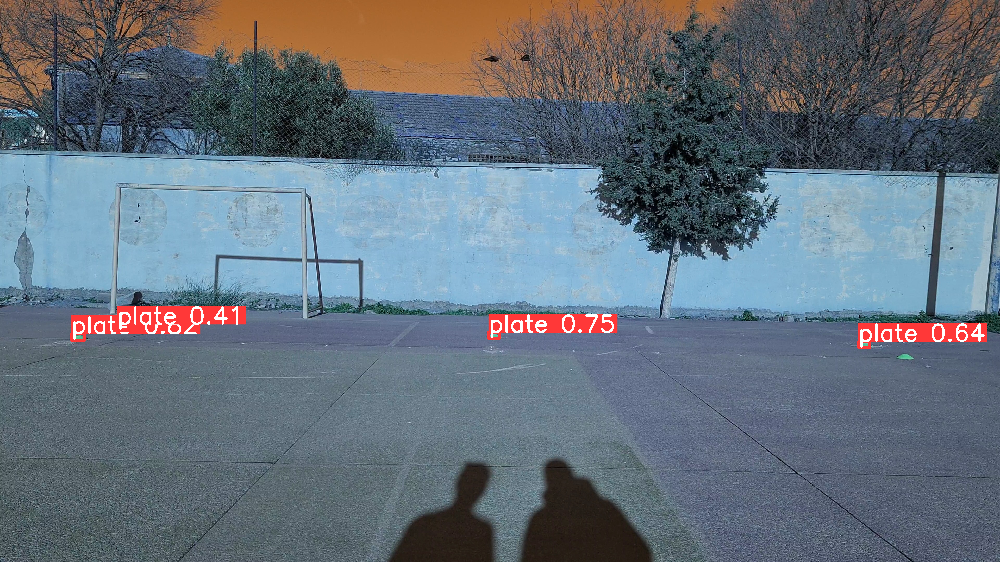

In [32]:
Image("demo_data/prediction_visual.png")

In [10]:
# Assuming result2.to_coco_annotations() is stored in the variable 'annotations'
annotations = result2.to_coco_annotations()

# Extract bbox coordinates with id
bbox_coordinates = [{"id": i, "bbox": item['bbox']} for i, item in enumerate(annotations)]

print(bbox_coordinates)

[{'id': 0, 'bbox': [549.22119140625, 218.48762321472168, 8.486251831054688, 4.175065994262695]}, {'id': 1, 'bbox': [312.4314956665039, 212.9154281616211, 8.092063903808594, 4.5309600830078125]}, {'id': 2, 'bbox': [45.26664352416992, 213.6934356689453, 10.348304748535156, 4.663302421569824]}, {'id': 3, 'bbox': [74.66024017333984, 207.73448181152344, 8.934791564941406, 4.187744140625]}, {'id': 4, 'bbox': [574.2955932617188, 225.8091049194336, 10.548248291015625, 5.460002899169922]}, {'id': 5, 'bbox': [207.02802348136902, 220.33746337890625, 2.792595624923706, 1.7638168334960938]}]


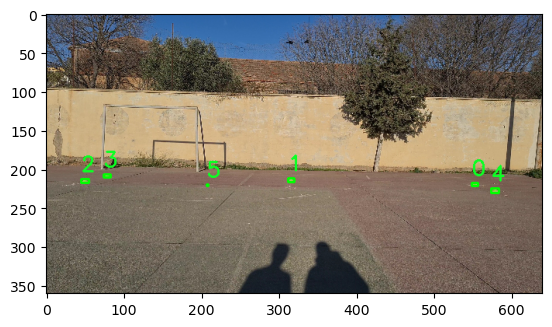

In [11]:
import cv2
import matplotlib.pyplot as plt

# Assuming bbox_coordinates is your list of bounding boxes with ids
bbox_coordinates = [{"id": i, "bbox": item['bbox']} for i, item in enumerate(annotations)]

# Draw each bounding box on the image
for bbox in bbox_coordinates:
    # Get the id and coordinates
    id = bbox['id']
    x, y, w, h = bbox['bbox']

    # Draw the rectangle
    cv2.rectangle(img, (int(x), int(y)), (int(x+w), int(y+h)), (0, 255, 0), 2)

    # Put the id
    cv2.putText(img, str(id), (int(x), int(y-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)

# Display the image
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()